In [1]:
#Generate a synthetic methane raster

In [2]:
pip install rasterio


  Using cached rasterio-1.5.2-cp314-cp314-win_amd64.whl.metadata (8.9 kB)
  Using cached affine-3.0.1-py3-none-any.whl.metadata (4.5 kB)
Using cached rasterio-1.5.2-cp314-cp314-win_amd64.whl (31.5 MB)
Using cached affine-3.0.1-py3-none-any.whl (10 kB)

   -------------------- ------------------- 1/2 [rasterio]
   -------------------- ------------------- 1/2 [rasterio]
   -------------------- ------------------- 1/2 [rasterio]
   -------------------- ------------------- 1/2 [rasterio]
   -------------------- ------------------- 1/2 [rasterio]
   -------------------- ------------------- 1/2 [rasterio]
   -------------------- ------------------- 1/2 [rasterio]
   -------------------- ------------------- 1/2 [rasterio]
   -------------------- ------------------- 1/2 [rasterio]
   -------------------- ------------------- 1/2 [rasterio]
   -------------------- ------------------- 1/2 [rasterio]
   ---------------------------------------- 2/2 [rasterio]

Note: you may need to restart the kern

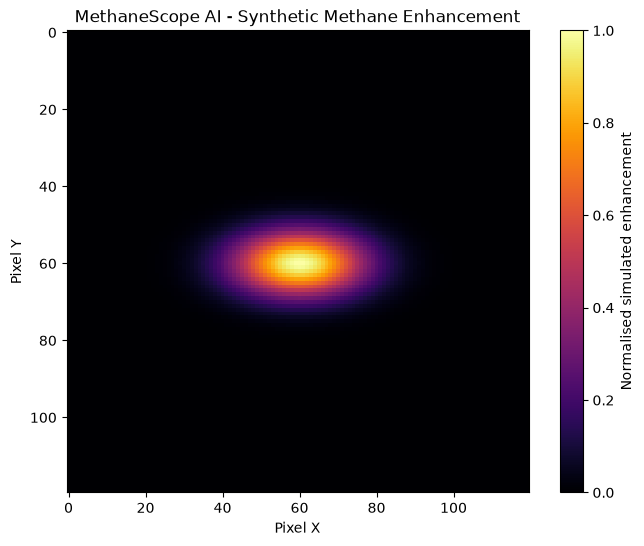

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Project directories
data_dir = Path("data/synthetic")
data_dir.mkdir(parents=True, exist_ok=True)

# Generate a synthetic grid
size = 120

x, y = np.meshgrid(
    np.arange(size),
    np.arange(size)
)

# Synthetic enhancement
enhancement = np.exp(
    -(
        ((x - 60) / 12) ** 2
        + ((y - 60) / 6) ** 2
    ) / 2
).astype("float32")

plt.figure(figsize=(8, 6))

plt.imshow(enhancement, cmap="inferno")
plt.colorbar(label="Normalised simulated enhancement")

plt.title("MethaneScope AI - Synthetic Methane Enhancement")
plt.xlabel("Pixel X")
plt.ylabel("Pixel Y")
plt.show()

In [4]:
#Save the Raster as GeoTIFF

In [5]:
import rasterio
from rasterio.transform import from_origin

# Illustrative geographical grid
# These are synthetic coordinates, not a real methane source.
transform = from_origin(
    west=28.0,
    north=-17.0,
    xsize=0.001,
    ysize=0.001
)

geotiff_path = data_dir / "synthetic_methane.tif"

with rasterio.open(
    geotiff_path,
    "w",
    driver="GTiff",
    height=enhancement.shape[0],
    width=enhancement.shape[1],
    count=1,
    dtype="float32",
    crs="EPSG:4326",
    transform=transform,
    compress="deflate"
) as dst:

    dst.write(enhancement, 1)
    dst.update_tags(
        data_origin="synthetic",
        units="dimensionless"
    )

print("GeoTIFF created:", geotiff_path)

GeoTIFF created: data\synthetic\synthetic_methane.tif


In [6]:
#Read GeoTiff

In [7]:
with rasterio.open(geotiff_path) as src:

    raster_data = src.read(1)

    print("Width:", src.width)
    print("Height:", src.height)
    print("Coordinate system:", src.crs)
    print("Bounds:", src.bounds)
    print("Data type:", src.dtypes[0])
    print("Metadata:", src.tags())

Width: 120
Height: 120
Coordinate system: EPSG:4326
Bounds: BoundingBox(left=28.0, bottom=-17.12, right=28.12, top=-17.0)
Data type: float32
Metadata: {'data_origin': 'synthetic', 'units': 'dimensionless', 'AREA_OR_POINT': 'Area'}


In [8]:
#Save measurements as NetCDF

In [9]:
import xarray as xr

longitude = 28.0 + (np.arange(size) + 0.5) * 0.001
latitude = -17.0 - (np.arange(size) + 0.5) * 0.001

dataset = xr.Dataset(
    {
        "simulated_enhancement": (
            ("latitude", "longitude"),
            enhancement
        )
    },
    coords={
        "latitude": latitude,
        "longitude": longitude
    },
    attrs={
        "source": "MethaneScope AI synthetic experiment",
        "description": "Educational synthetic dataset"
    }
)

dataset["simulated_enhancement"].attrs["units"] = "dimensionless"

netcdf_path = data_dir / "synthetic_methane.nc"

dataset.to_netcdf(netcdf_path)

print(dataset)
print("\nSaved:", netcdf_path)

<xarray.Dataset> Size: 60kB
Dimensions:                (latitude: 120, longitude: 120)
Coordinates:
  * latitude               (latitude) float64 960B -17.0 -17.0 ... -17.12 -17.12
  * longitude              (longitude) float64 960B 28.0 28.0 ... 28.12 28.12
Data variables:
    simulated_enhancement  (latitude, longitude) float32 58kB 7.188e-28 ... 5...
Attributes:
    source:       MethaneScope AI synthetic experiment
    description:  Educational synthetic dataset

Saved: data\synthetic\synthetic_methane.nc


In [10]:
#Create a GeoJSON feature

In [11]:
import json

center_lon = float(longitude[size // 2])
center_lat = float(latitude[size // 2])

d = 0.02

polygon = [
    [center_lon - d, center_lat - d],
    [center_lon + d, center_lat - d],
    [center_lon + d, center_lat + d],
    [center_lon - d, center_lat + d],
    [center_lon - d, center_lat - d]
]

feature_collection = {
    "type": "FeatureCollection",
    "features": [
        {
            "type": "Feature",
            "properties": {
                "source_id": "SYNTHETIC_001",
                "source": "MethaneScope AI",
                "data_type": "synthetic",
                "measurement_status": "simulated"
            },
            "geometry": {
                "type": "Polygon",
                "coordinates": [polygon]
            }
        }
    ]
}

geojson_path = data_dir / "synthetic_plume.geojson"

with open(geojson_path, "w", encoding="utf-8") as file:
    json.dump(feature_collection, file, indent=2)

print("GeoJSON created:", geojson_path)

GeoJSON created: data\synthetic\synthetic_plume.geojson


In [12]:
#Verify all 3 outputs

In [13]:
files = [
    geotiff_path,
    netcdf_path,
    geojson_path
]

for file_path in files:
    print(
        file_path.name,
        "| Exists:", file_path.exists(),
        "| Size:", file_path.stat().st_size, "bytes"
    )

synthetic_methane.tif | Exists: True | Size: 35912 bytes
synthetic_methane.nc | Exists: True | Size: 59984 bytes
synthetic_plume.geojson | Exists: True | Size: 801 bytes
